# LuminaMetrics Capstone: GlobalMart Q4 Sales Analysis

Welcome to your capstone project at LuminaMetrics! As a junior Data Consultant on the E-commerce Analytics team, you will clean, debug, and visualize a raw Q4 sales extract for our client, **GlobalMart**.

**Objective:** Resolve structural anomalies, ensure homogeneous datatypes in arrays, and deploy an interactive executive dashboard.

**Folder layout:** this notebook lives in `notebooks/`, reads `../data/q4_sales_data.csv` and writes `../output/dashboard.html`, so run it from the `notebooks/` folder.

### Setup: Import Libraries
**Logic:** Import Pandas (tables), NumPy (boolean masking), Matplotlib (static chart) and Plotly Express (interactive chart), and apply Matplotlib's `ggplot` style for a clean look.

**Expected output:** none (the cell only prepares the environment).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import plotly.express as px

# Set up basic matplotlib style
plt.style.use('ggplot')

## Step 1: Data Loading & Shape Evaluation
**Logic:** Load GlobalMart's `q4_sales_data.csv` into a DataFrame named `raw_sales`, then print its dimensions with `.shape` and its column datatypes with `.dtypes` to check that every column holds one consistent type. Finally, preview the first rows.

**Expected output:** `(500, 6)` (500 transactions, 6 columns). `Quantity` is an integer, but `Revenue` shows as a string (`object`/`str`) because of the `$` signs, which is the anomaly fixed in Step 2. The preview shows rows like `TXN-1001 ... $599.98`.

In [2]:
raw_sales = pd.read_csv('../data/q4_sales_data.csv')

# Initial array dimensions (rows, columns)
print('Initial shape:', raw_sales.shape)

# Verify datatypes of each column
print('\nColumn datatypes:')
print(raw_sales.dtypes)

# Inspect the first few rows to understand the data
raw_sales.head()

Initial shape: (500, 6)

Column datatypes:
Transaction_ID        str
Date                  str
Region                str
Product_Category      str
Quantity            int64
Revenue               str
dtype: object


,Transaction_ID,Date,Region,Product_Category,Quantity,Revenue
0,TXN-1001,2023-10-01,North America,Electronics,2,$599.98
1,TXN-1002,2023-10-01,Europe,Apparel,5,$125.00
2,TXN-1003,2023-10-01,Asia-Pacific,Home & Garden,1,$45.00
3,TXN-1004,2023-10-02,Latin America,Sports,3,$150.75
4,TXN-1005,2023-10-02,Middle East,Toys,4,$89.96


## Step 2: Datatype Conversion (Homogeneous Datatypes)
The executives noted that the `Revenue` column is failing in financial calculations because it is stored as a string with currency symbols.

**Logic:** Use element-wise string methods (`.str.replace`) to remove the `$` symbol and any commas, then convert the cleaned text to a `float` with `.astype(float)`. Negative amounts such as `-$299.99` become `-299.99`, so their sign is preserved. The replacement uses `regex=False` because `$` is a special character in regular expressions.

**Expected output:** the dtype changes from string/object to `float64`, with no missing values created by the conversion and a total of about 58,731.62 (this raw total still includes invalid records).

In [3]:
# Remove the currency symbol ('$') and commas (',') element-wise, then convert to float
raw_sales['Revenue'] = (
    raw_sales['Revenue']
    .str.replace('$', '', regex=False)
    .str.replace(',', '', regex=False)
    .astype(float)
)

# Verify the conversion was successful
print('Revenue dtype:', raw_sales['Revenue'].dtype)
print('Missing values in Revenue:', raw_sales['Revenue'].isna().sum())
print('Raw total revenue (before cleaning):', round(raw_sales['Revenue'].sum(), 2))

Revenue dtype: float64
Missing values in Revenue: 0
Raw total revenue (before cleaning): 58731.62


## Step 3: Boolean Masking
The raw data contains invalid records where `Quantity` is less than or equal to 0 (system errors or returns). They must be filtered out before analysis.

**Logic:** Build a boolean mask with NumPy that is `True` only where `Quantity > 0`, and use it to keep just those rows in a new DataFrame, `cleaned_sales` (`.copy()` makes it independent of `raw_sales`, which avoids pandas `SettingWithCopy` warnings). Then prove the result is clean.

**Expected output:** 113 invalid rows are removed (75 negative and 38 zero quantities), leaving a cleaned shape of `(387, 6)`, and the check confirms exactly 0 rows with `Quantity <= 0`.

In [4]:
# Boolean mask: True for valid records (Quantity > 0)
valid_mask = np.greater(raw_sales['Quantity'].to_numpy(), 0)

# Keep only the valid records
cleaned_sales = raw_sales[valid_mask].copy()

# Verify the new shape to see how many rows were dropped
print('Raw data shape:    ', raw_sales.shape)
print('Cleaned data shape:', cleaned_sales.shape)
print('Rows dropped:      ', len(raw_sales) - len(cleaned_sales),
      f"(negative: {(raw_sales['Quantity'] < 0).sum()}, zero: {(raw_sales['Quantity'] == 0).sum()})")

# Data integrity check: no zero or negative quantities may remain
invalid_remaining = (cleaned_sales['Quantity'] <= 0).sum()
print('Rows with Quantity <= 0 after masking:', invalid_remaining)
assert invalid_remaining == 0

Raw data shape:     (500, 6)
Cleaned data shape: (387, 6)
Rows dropped:       113 (negative: 75, zero: 38)
Rows with Quantity <= 0 after masking: 0


## Step 4: Visualization Strategy Brief
Before building the visual assets, here is the strategy for the executive board meeting.

**Why a Bar Chart for the categorical `Region` data?**
- `Region` is a categorical variable: a handful of separate, unordered groups (North America, Europe, Asia-Pacific, Latin America, Middle East) with no numeric scale between them.
- The business question is a comparison across groups ("which region sells the most?"). A bar chart gives each category its own bar, and because bar length starts at zero, differences in total sales can be judged at a glance and ranked when the bars are sorted.

**Why a Histogram for the continuous `Revenue` data?**
- `Revenue` is continuous: it can take any value in a range, so there is no natural list of categories to give each a bar.
- A histogram groups the values into equal-width bins and shows how many transactions fall into each, which reveals the *distribution* of the data: where most transactions sit, whether it is skewed, and whether there are outliers (for example, many small orders and a few very large ones). That is the typical use case for a histogram with continuous data, before moving on to relationships.
- We then deploy a **scatter plot** next because the question changes from "how is one variable distributed?" to "how do two numeric variables (`Quantity` and `Revenue`) relate?".

## Step 5: Interactive Dashboard Deployment
Build the visual assets for the stakeholder presentation. Start with a static summary chart using Matplotlib, then deploy a dynamic Plotly visual.

### 5a. Static bar chart: total sales by region
**Logic:** Group `cleaned_sales` by `Region`, sum `Revenue`, and sort from highest to lowest so the ranking is obvious. Draw a bar chart with Matplotlib that has a descriptive title, labeled X and Y axes, dollar-formatted Y tick labels, visible tick marks and light gridlines only (no extra decoration).

**Expected output:** a table of regional totals, then one bar per region. North America is the tallest bar (about $31,950), followed by Latin America (about $12,616), Asia-Pacific ($10,335), Europe ($5,500) and Middle East (about $4,790).

Region
North America    31949.97
Latin America    12616.25
Asia-Pacific     10335.00
Europe            5500.00
Middle East       4790.37
Name: Revenue, dtype: float64


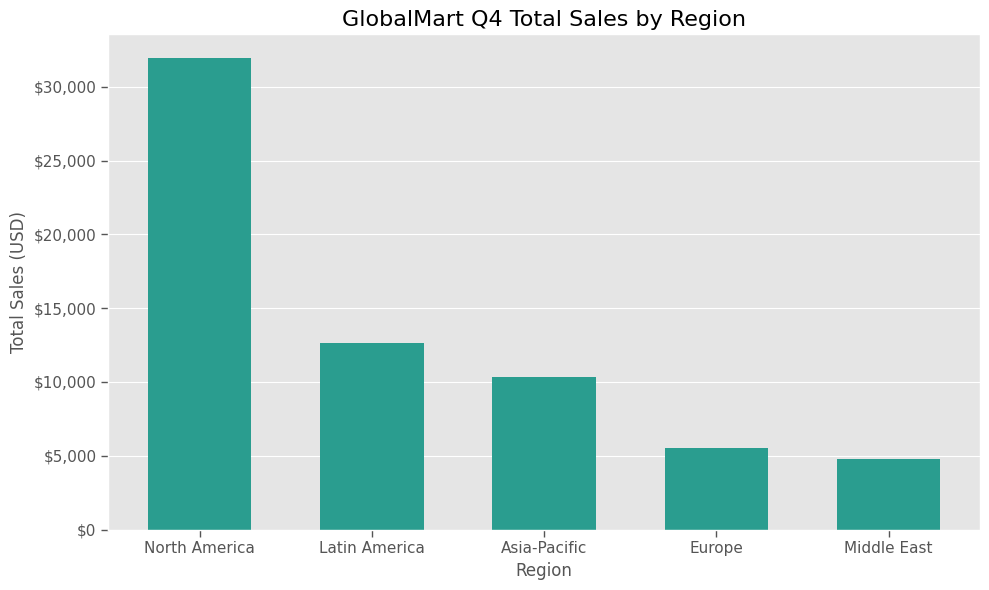

In [5]:
# Total sales (Revenue) grouped by Region, highest first
region_sales = (
    cleaned_sales.groupby('Region')['Revenue']
    .sum()
    .sort_values(ascending=False)
)
print(region_sales.round(2))

# Static bar chart with Matplotlib
fig_bar, ax = plt.subplots(figsize=(10, 6))
ax.bar(region_sales.index, region_sales.values, color='#2a9d8f', width=0.6)

ax.set_title('GlobalMart Q4 Total Sales by Region', fontsize=16)
ax.set_xlabel('Region', fontsize=12)
ax.set_ylabel('Total Sales (USD)', fontsize=12)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'${v:,.0f}'))
ax.tick_params(axis='both', which='major', length=5, width=1, direction='out',
               bottom=True, left=True, labelsize=11)
ax.grid(axis='x', visible=False)

plt.tight_layout()
plt.show()

### 5b. Interactive scatter plot: Quantity vs. Revenue
**Logic:** Use Plotly Express to plot each cleaned transaction as a point, with `Quantity` on the X-axis and `Revenue` on the Y-axis. Hover tooltips display the `Product_Category` (plus the `Region` and the exact values), and points are colored by product category so executives can click the legend to isolate a category, and zoom or pan to explore. The chart gets a descriptive title, labeled axes, whole-number Quantity ticks and a clean white template. It is then exported to `../output/dashboard.html`, a self-contained file that works in any browser without Python.

**Expected output:** an interactive scatter of 387 points that sit in vertical strips at Quantity 1 to 6, with Electronics spreading highest on Revenue; the cell also prints a confirmation that `dashboard.html` was written.

In [6]:
from pathlib import Path
Path('../output').mkdir(exist_ok=True)

fig = px.scatter(
    cleaned_sales,
    x='Quantity',
    y='Revenue',
    color='Product_Category',
    hover_data={'Product_Category': True, 'Region': True,
                'Quantity': True, 'Revenue': ':$,.2f'},
    title='GlobalMart Q4: Quantity vs. Revenue by Transaction',
    labels={'Quantity': 'Quantity (units)', 'Revenue': 'Revenue (USD)',
            'Product_Category': 'Product category'},
    opacity=0.7,
    template='plotly_white'
)

fig.update_xaxes(dtick=1, showline=True, ticks='outside')
fig.update_yaxes(tickprefix='$', tickformat=',', showline=True, ticks='outside')

# Show the interactive plot inline
fig.show()

# Export the interactive scatter plot for stakeholder distribution
fig.write_html('../output/dashboard.html')
print('Exported ../output/dashboard.html')

Exported ../output/dashboard.html


## Summary of Findings
- **Data quality:** 113 of 500 records (22.6%) were invalid: 75 negative quantities (returns or errors) and 38 zero quantities. Their revenue totaled -$6,459.97, so removing them changes total revenue from about $58,731.62 to **$65,191.59** across 387 valid transactions.
- **Top region:** North America generates about $31,950, roughly **49%** of valid revenue, followed by Latin America (about 19%), Asia-Pacific (about 16%), Europe (about 8%) and Middle East (about 7%).
- **Caveat:** in this extract every region sells exactly one product category (North America = Electronics, Latin America = Sports, Asia-Pacific = Home & Garden, Europe = Apparel, Middle East = Toys), so regional and category effects cannot be separated.
- **Caveat:** filtering out the invalid records also removes returns, so the cleaned revenue is gross sales rather than net of returns.
- **Data quality by region:** Middle East has the most invalid records (31 versus about 20 in each other region).